### 4.1.3 Scenario #2
**Second scenario:** "Design a 3-department campus with Finance, Sales, and IT."

As part of the process, the planning agent clarified requirements from the user. We observed that while the agent successfully generated topologies when users provided explicit setup details (clear requirements), it failed when users asked for recommendations (unclear requirements).

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('scenario_runs.csv')
df.head()

,Run #,Requirements Clear?,Questions Asked?,Design Generated?,Retries,Runtime (Seconds),Result
0,1,No,1,No,0,2.704,Needs Clarification
1,2,No,1,No,0,1.123,Needs Clarification
2,3,No,1,No,0,1.242,Needs Clarification
3,4,No,1,No,0,1.584,Needs Clarification
4,5,No,0,No,0,5.446,Error: 'NoneType' object has no attribute 'nodes'


#### Analysis of Result Outcomes Based on Questions Asked?

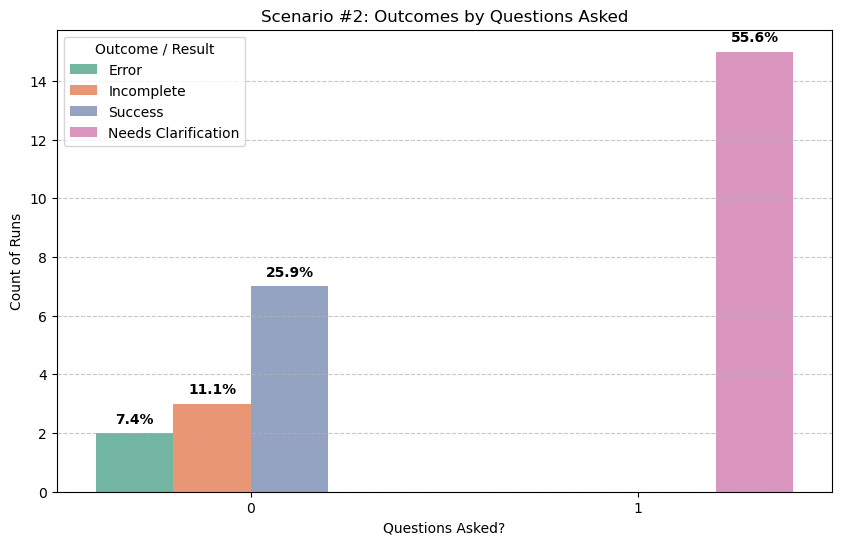

In [2]:
df['Result'] = df['Result'].replace({"Error: 'NoneType' object has no attribute 'nodes'": "Error"})

plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='Questions Asked?', hue='Result', palette='Set2')
plt.title('Scenario #2: Outcomes by Questions Asked')
plt.ylabel('Count of Runs')
plt.legend(title='Outcome / Result')
plt.grid(axis='y', linestyle='--', alpha=0.7)

total = len(df)
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height/total:.1%}', (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', xytext=(0, 5),
                    textcoords='offset points', fontweight='bold')

plt.show()

#### Topology Generation Success Rate
We consider success to be when the `Design Generated?` feature evaluates to `Yes`.

C:\Users\96653\AppData\Local\Temp\ipykernel_23364\277777406.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=success_stats, x='Requirements Clear?', y='Success Rate (%)', palette='viridis')


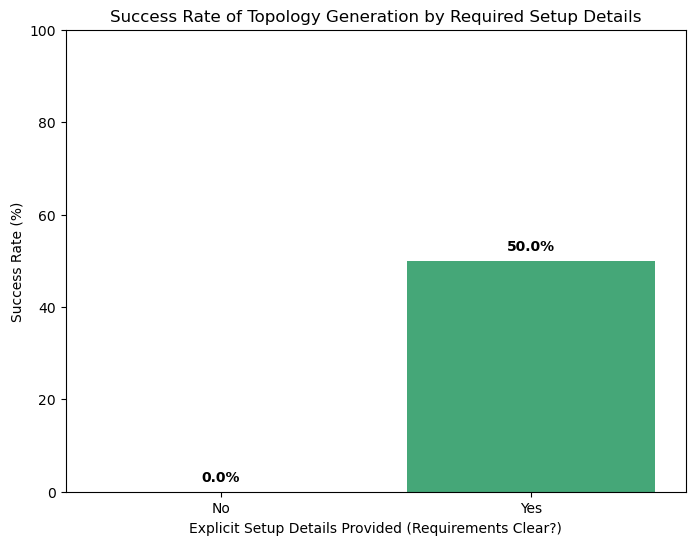

In [3]:
# Calculate success rate
df['Success'] = df['Design Generated?'] == 'Yes'
success_stats = df.groupby('Requirements Clear?')['Success'].agg(['count', 'mean']).reset_index()
success_stats['Success Rate (%)'] = success_stats['mean'] * 100

plt.figure(figsize=(8, 6))
ax = sns.barplot(data=success_stats, x='Requirements Clear?', y='Success Rate (%)', palette='viridis')
plt.title('Success Rate of Topology Generation by Required Setup Details')
plt.xlabel('Explicit Setup Details Provided (Requirements Clear?)')
plt.ylabel('Success Rate (%)')
plt.ylim(0, 100)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10),
                textcoords='offset points', fontweight='bold')

plt.show()